# KAN on alcohol deoxyfluorination with sulfonyl fluorides

**Source.** Nielsen, Ahneman, Riera, Doyle, *JACS* **2018**, *140*, 5004-5008
(DOI 10.1021/jacs.8b01523). Data and the paper's descriptors from the Doyle lab `ochem-data`
repository (`deoxyF/rxns/dft_from_paper/all.csv`).

**Reaction.** Deoxyfluorination of 37 alcohols with 5 sulfonyl fluorides and 4 organic bases:
740 reactions. The alcohol is first sulfonylated (the base deprotonates it, the sulfonyl fluoride
transfers its sulfonyl group), then the released fluoride displaces the sulfonate. Primary and
unhindered secondary alcohols follow this path cleanly; hindered and tertiary alcohols eliminate
or do not react.

**The paper's finding.** A random forest on 24 descriptors predicted yield across alcohol classes
(R$^2$ about 0.9 in the paper's held-out set) and ranked the alcohol's substitution class and the
base's descriptor as the main contributors; the best base and sulfonyl fluoride depend on the
alcohol class, which is the kind of interaction a one-descriptor rule cannot carry.

**Descriptors used here.** The paper's 24: four continuous alcohol descriptors (C1 charge, C1
exposed area, electronegativity) and sixteen 0/1 structural flags (primary, secondary, tertiary,
ring sizes, benzylic, allylic, carbonyl positions, hemiacetal, alpha-amino), one base descriptor
(N1 exposed area) and three sulfonyl fluoride charges (S1, F1, O1).

**Target.** Yield in percent, regression. Success for the threshold rules: above 40 % yield.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Response curves that survive refitting.** Near-duplicate descriptors are pruned first, so
   an effect is not split between interchangeable columns. Each top descriptor then gets an
   accumulated local effect curve in its own units, with the linear baseline and the envelope
   of five refits, and the location of any step or window edge. A shape that changes from
   fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    accumulated_local_effects,
    accumulated_local_effects_cv,
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    prune_collinear,
    sensitivity,
    threshold_rules,
    transitions,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the paper's descriptor table

Flags constant over the dataset are dropped. Flags are kept as 0/1 descriptors; their response
curves are two-point lines and are read as such.


In [2]:
URL = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/deoxyF/rxns/dft_from_paper/all.csv"
raw = pd.read_csv(URL)
X_df = raw.drop(columns=["index", "yield"]).copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
COMPONENT = {c: ("alcohol" if c.startswith("alcohol") else "base" if c.startswith("base") else "sulfonyl fluoride") for c in X_df.columns}
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 40.0).astype(int)
SUCCESS_RULE = "yield above 40 %"
n_alc = raw[[c for c in raw.columns if c.startswith("alcohol")]].drop_duplicates().shape[0]
print(f"{len(raw)} reactions: {n_alc} alcohols x {raw['base_.N1_exposed_area'].nunique()} bases x {raw['sulfonyl_fluoride_.S1_electrostatic_charge'].nunique()} sulfonyl fluorides")
cls = np.select([raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1], ["primary", "secondary", "tertiary"], "other")
print(pd.DataFrame({"class": cls, "yield": y}).groupby("class")["yield"].agg(["mean", "count"]).round(1))

# Descriptors a published hypothesis names; kept first when duplicates are pruned.
HYPOTHESIS = []
HYPOTHESIS_CONTEXT = []


Dropped constant descriptors: []
740 reactions: 37 alcohols x 4 bases x 4 sulfonyl fluorides
           mean  count
class                 
primary    49.7    320
secondary  36.5    380
tertiary    3.3     40


740 reactions, 23 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 40 % (48% of reactions).


,Component,Distinct,Min,Max
alcohol_.C1_electrostatic_charge,alcohol,36,-0.112,0.808
alcohol_.C1_exposed_area,alcohol,37,0.841,16.405
alcohol_electronegativity,alcohol,9,0.090,0.170
alcohol_primary,alcohol,2,0.000,1.000
alcohol_secondary,alcohol,2,0.000,1.000
alcohol_tertiary,alcohol,2,0.000,1.000
alcohol_cyclic,alcohol,2,0.000,1.000
alcohol_4.membered_ring,alcohol,2,0.000,1.000
alcohol_5.membered_ring,alcohol,2,0.000,1.000
alcohol_6.membered_ring,alcohol,2,0.000,1.000


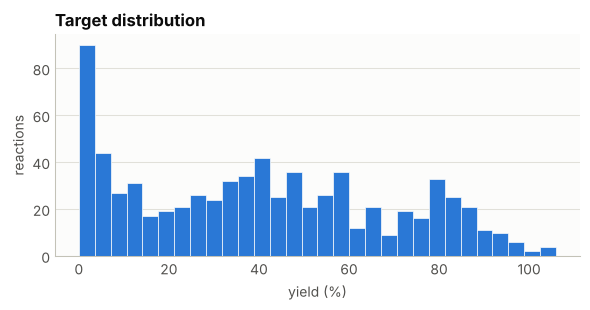

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


### 1.1 One descriptor per group of near-duplicates

Two descriptors that are near copies of each other (absolute correlation above 0.85) split one
effect between them arbitrarily, so a curve for either one is not identifiable. The pipeline
keeps the first descriptor of each group, the one the source paper names when there is one,
and drops the rest for every model.


In [4]:
PRUNE_R = 0.85
kept, dropped = prune_collinear(X, feature_names, PRUNE_R, keep_first=HYPOTHESIS)
for name, (partner, r) in dropped.items():
    print(f"dropped {name}: |r| = {r:.2f} with {partner}, which stays")
if not dropped:
    print(f"No pair of descriptors correlates above {PRUNE_R}; all {n_features} stay.")
X_df = X_df[kept]
feature_names = kept
X = X_df.to_numpy(dtype=float)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}
print(f"{n_features} descriptors go into every model.")


dropped alcohol_primary: |r| = 0.90 with alcohol_.C1_exposed_area, which stays
dropped sulfonyl_fluoride_.O1_electrostatic_charge: |r| = 0.90 with sulfonyl_fluoride_.F1_electrostatic_charge, which stays
21 descriptors go into every model.


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?

The KAN carries light L1 and entropy penalties on its spline coefficients, at the same strength
(1e-3) in every notebook of the series. That strength was chosen once, on three of the datasets,
as the largest that cost no cross-validated accuracy: the benchmark stayed at R² 0.984, and the
deoxyfluorination and ligand sets improved. Ten times more cost accuracy on both regression sets.


Model                  r2               other
MLR                    0.495 ± 0.047   16.219 ± 0.674 (mae)
Random Forest          0.907 ± 0.011   6.184 ± 0.381 (mae)
Gradient Boosting      0.931 ± 0.014   5.530 ± 0.383 (mae)
KAN                    0.855 ± 0.029   8.053 ± 0.675 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0764 ± 0.0305, KAN better in 0/15, Wilcoxon p = 6.1e-05
(128 s)


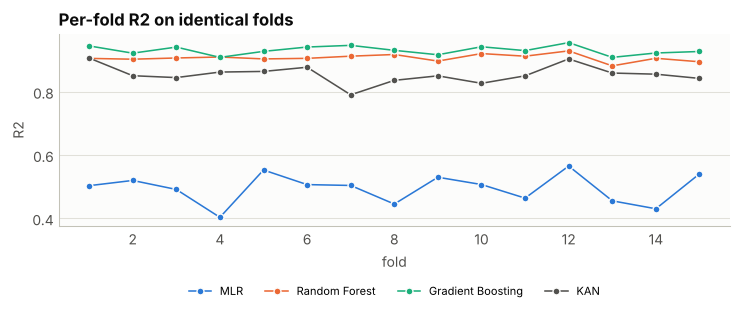

In [5]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_REG = 1e-3  # L1 and entropy penalty on the spline coefficients
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(
        layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3, l1_spline=KAN_REG, entropy_reg=KAN_REG
    )


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 592 train / 148 test


,Test R2,Test MAE
Model,,
MLR,0.504,16.882
Random Forest,0.909,6.320
Gradient Boosting,0.941,5.540
KAN,0.895,7.100


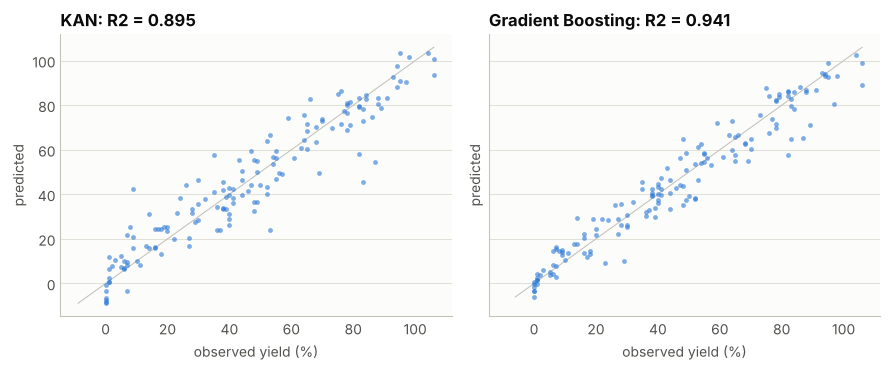

In [6]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.534
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,alcohol_.C1_electrostatic_charge,0.198,0.635,0.635,0.667,0.633
1,alcohol_cyclic,0.500,0.608,0.622,0.610,0.810
2,base_.N1_exposed_area,6.733,0.604,0.622,0.602,0.861
3,alcohol_benzylic,0.500,0.583,0.568,0.683,0.354
4,alcohol_.C1_exposed_area,12.267,0.580,0.574,0.629,0.494
5,sulfonyl_fluoride_.F1_electrostatic_charge,-0.180,0.579,0.561,0.706,0.304
6,alcohol_6.membered_ring,0.500,0.575,0.601,0.576,0.962
7,alcohol_allylic,0.500,0.573,0.601,0.574,0.987
8,alcohol_alpha.amino,0.500,0.560,0.534,0.778,0.177
9,alcohol_tertiary,0.500,0.543,0.574,0.556,1.000


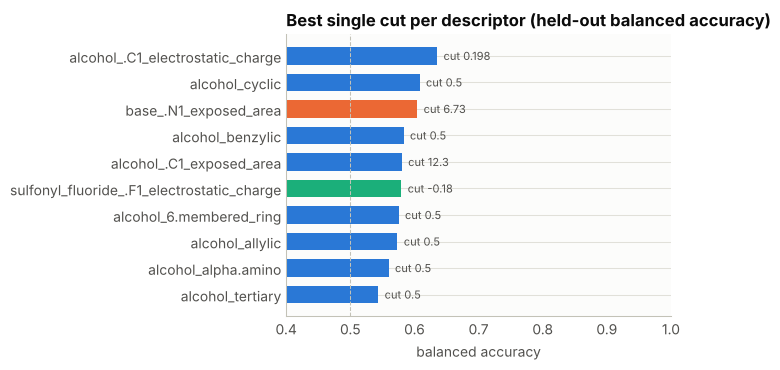

In [7]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Response curves, read as accumulated local effects

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors, among those with at least five
distinct values, then get a response curve in their own units.

The curve is an accumulated local effect rather than a partial effect. A partial effect holds
every other descriptor at its mean, which describes a compound that does not exist, and when
descriptors are correlated it asks the model about combinations it never saw. The accumulated
local effect moves a descriptor only within the reactions that already sit near each value and
adds up the local changes (Apley and Zhu, *J. R. Stat. Soc. B* 2020). The cell after the curves
puts the two readings side by side.

Each curve comes with the linear baseline read the same way, the envelope of five refits on
disjoint folds, and the observed values along the bottom. The curve is centred on the model's
mean prediction and adds up local changes, so at a sparsely sampled end it can leave the range of
the target: a probability curve that dips below zero there says "few reactions, still falling",
not that a probability is negative.


,Feature,Component,Sensitivity
0,alcohol_.C1_electrostatic_charge,alcohol,45.1134
1,alcohol_electronegativity,alcohol,40.5225
2,sulfonyl_fluoride_.S1_electrostatic_charge,sulfonyl fluoride,27.3375
3,sulfonyl_fluoride_.F1_electrostatic_charge,sulfonyl fluoride,22.4012
4,alcohol_beta_carbonyl,alcohol,22.2305
5,alcohol_cyclic,alcohol,21.8936
6,alcohol_.C1_exposed_area,alcohol,18.6991
7,alcohol_tertiary,alcohol,16.9147
8,alcohol_allylic,alcohol,16.7642
9,alcohol_5.membered_ring,alcohol,15.2348


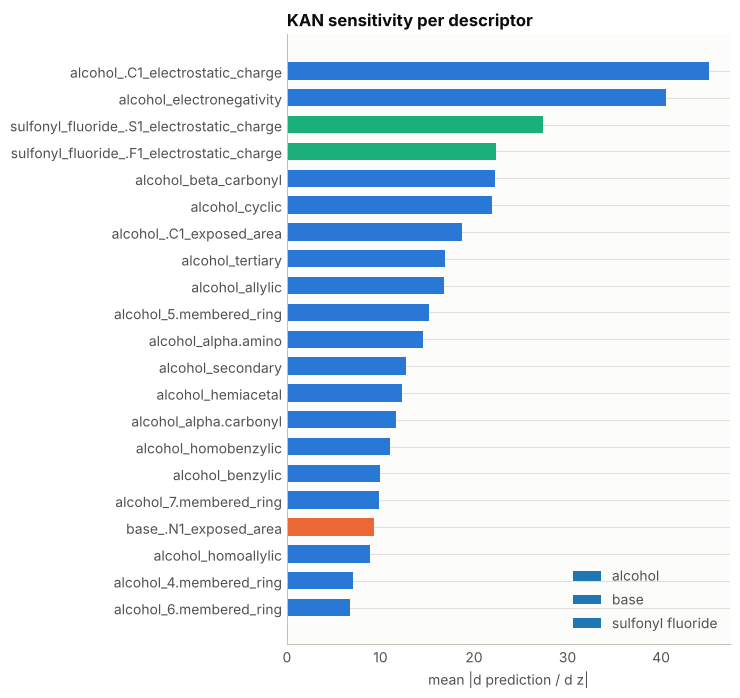

4 descriptors with at least 5 distinct values; 17 with fewer, shown as levels below.


curves and fold envelopes: 76 s


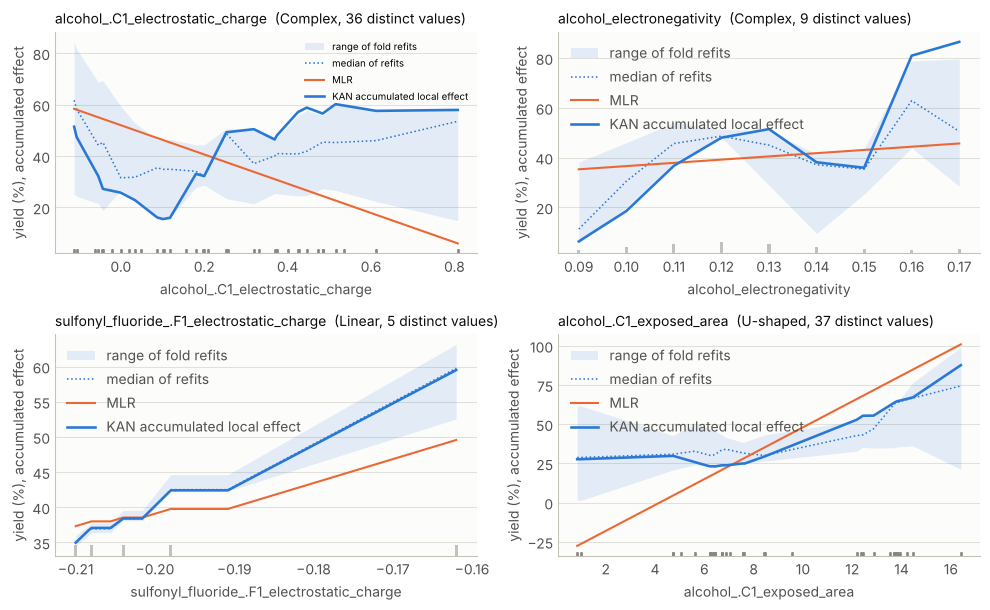

In [8]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in a later cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0
# An accumulated local effect is centred on the mean prediction and adds up local changes, so
# at a sparsely sampled end it can leave the range of the target (below 0 for a probability).
ALE_LABEL = f"{Y_LABEL}, accumulated effect"

t0 = time.time()
effects = accumulated_local_effects(
    kan, X, feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
effects = accumulated_local_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"curves and fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=ALE_LABEL)
    label = effects[f].shape(scale=SHAPE_SCALE)[0]
    ax.set_title(f"{f}  ({label}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


,Feature,Partial effect,Refits agreeing (PE),Accumulated local effect,Refits agreeing (ALE)
0,alcohol_.C1_electrostatic_charge,Complex,0.4,Complex,0.2
1,alcohol_electronegativity,Complex,0.8,Complex,1.0
2,sulfonyl_fluoride_.F1_electrostatic_charge,Inverted U,0.2,Linear,1.0
3,alcohol_.C1_exposed_area,Linear,0.0,U-shaped,0.2


Mean fraction of refits agreeing on the shape: partial effect 0.35, accumulated local effect 0.60


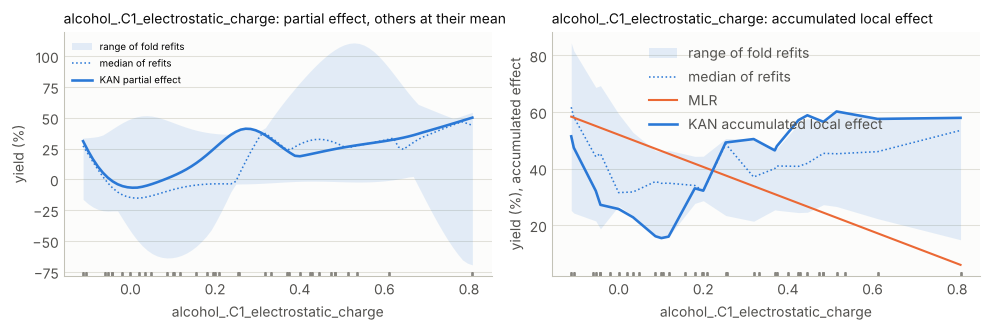

In [9]:
# The same KAN read both ways, with the same five refits behind each envelope.
pd_effects = partial_effects(kan, X, feature_names, top_features, scaler=scaler, task=TASK)
pd_effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=pd_effects, verbose=False,
)  # fmt: skip


def agreement(pe):
    """The full fit's shape label, and the fraction of refits that share it."""
    label = pe.shape(scale=SHAPE_SCALE)[0]
    folds = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
    return label, float(np.mean([lab == label for lab in folds]))


rows = []
for f in top_features:
    s_pe, a_pe = agreement(pd_effects[f])
    s_ale, a_ale = agreement(effects[f])
    rows.append(
        {
            "Feature": f,
            "Partial effect": s_pe,
            "Refits agreeing (PE)": a_pe,
            "Accumulated local effect": s_ale,
            "Refits agreeing (ALE)": a_ale,
        }
    )
reading_cmp = pd.DataFrame(rows)
display(reading_cmp.round(2))
print(
    f"Mean fraction of refits agreeing on the shape: partial effect "
    f"{reading_cmp['Refits agreeing (PE)'].mean():.2f}, accumulated local effect "
    f"{reading_cmp['Refits agreeing (ALE)'].mean():.2f}"
)

f0 = top_features[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_partial_effect(axes[0], pd_effects[f0], ylabel=Y_LABEL)
plot_partial_effect(axes[1], effects[f0], ylabel=ALE_LABEL)
for ax, how in zip(axes, ["partial effect, others at their mean", "accumulated local effect"]):
    ax.set_title(f"{f0}: {how}", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


In [10]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,alcohol_secondary,alcohol,0.000,360,44.528,43.593
1,alcohol_secondary,alcohol,1.000,380,36.524,34.970
2,alcohol_tertiary,alcohol,0.000,700,42.537,41.345
3,alcohol_tertiary,alcohol,1.000,40,3.325,2.876
4,alcohol_cyclic,alcohol,0.000,500,45.922,44.752
5,alcohol_cyclic,alcohol,1.000,240,28.950,27.874
6,alcohol_4.membered_ring,alcohol,0.000,720,40.950,39.855
7,alcohol_4.membered_ring,alcohol,1.000,20,21.250,14.815
8,alcohol_5.membered_ring,alcohol,0.000,620,40.548,39.159
9,alcohol_5.membered_ring,alcohol,1.000,120,39.742,39.019


Observed spread across the levels of each few-level descriptor:
Feature
alcohol_tertiary                              39.2
alcohol_homoallylic                           38.4
alcohol_beta_carbonyl                         33.9
alcohol_6.membered_ring                       26.5
alcohol_allylic                               26.1
alcohol_4.membered_ring                       19.7
alcohol_cyclic                                17.0
sulfonyl_fluoride_.S1_electrostatic_charge    16.7
base_.N1_exposed_area                         14.0
alcohol_benzylic                              13.4
alcohol_alpha.carbonyl                        11.6
alcohol_homobenzylic                          11.0
alcohol_alpha.amino                           10.9
alcohol_7.membered_ring                       10.6
alcohol_secondary                              8.0
alcohol_hemiacetal                             6.0
alcohol_5.membered_ring                        0.8


In [11]:
# Shape of the full fit, whether the five refits agree on it, and where its edges are.
# A curve whose range is under 5 % of the target's spread is "Constant" whatever its wiggles.
EDGED = {"Step", "Window", "Gap", "Saturating"}


def edge_range(values):
    values = [v for v in values if v is not None]
    if not values:
        return ""
    return f"{min(values):.3g} to {max(values):.3g} ({len(values)} of 5)"


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, _ = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        tr = transitions(pe.x_raw, pe.y)
        folds = [transitions(pe.x_raw, c) for c in pe.curves]
        edged = label in EDGED
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Rise": tr["rise"] if edged else None,
                "Fall": tr["fall"] if edged else None,
                "Rise in refits": edge_range([t["rise"] for t in folds]) if edged else "",
                "Fall in refits": edge_range([t["fall"] for t in folds]) if edged else "",
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: full fit {r.Shape}; refits {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Rise,Fall,Rise in refits,Fall in refits,Fold shapes
0,alcohol_.C1_electrostatic_charge,alcohol,Complex,0.748,0.2,1.113,None,None,,,"Gap, Linear, Step, Step, Complex"
1,alcohol_electronegativity,alcohol,Complex,0.497,1.0,0.509,None,None,,,"Complex, Complex, Complex, Complex, Complex"
2,sulfonyl_fluoride_.F1_electrostatic_charge,sulfonyl fluoride,Linear,0.146,1.0,0.107,None,None,,,"Linear, Linear, Linear, Linear, Linear"
3,alcohol_.C1_exposed_area,alcohol,U-shaped,0.452,0.2,0.638,None,None,,,"U-shaped, Complex, Step, Step, Linear"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  sulfonyl_fluoride_.F1_electrostatic_charge: Linear
Shapes that do not:
  alcohol_.C1_electrostatic_charge: full fit Complex; refits Gap, Linear, Step, Step, Complex
  alcohol_electronegativity: full fit Complex; refits Complex, Complex, Complex, Complex, Complex
  alcohol_.C1_exposed_area: full fit U-shaped; refits U-shaped, Complex, Step, Step, Linear


## 5. Check against the chemistry

Three mechanism-level expectations: tertiary alcohols should fail (elimination beats S$_N$2),
the base effect should depend on the alcohol class, and the sulfonyl fluoride's electrophilicity
(S1 charge) should matter for the sulfonylation step. The cells below take the group means
straight from the data and put the base and sulfonyl fluoride means beside the KAN curves.


Mean yield by alcohol class and base (N1 exposed area):
base       4.727  5.305  6.069  7.397
class                                
primary     57.9   60.0   48.9   31.9
secondary   36.7   36.6   39.8   33.0
tertiary     2.5    3.3    4.6    2.9

Mean yield by alcohol class and sulfonyl fluoride (S1 charge):
SF         0.849  0.926  0.973  0.978
class                                
primary     45.5   51.3   49.4   52.8
secondary   29.7   56.1   30.8   35.2
tertiary     1.4   12.2    0.9    1.1


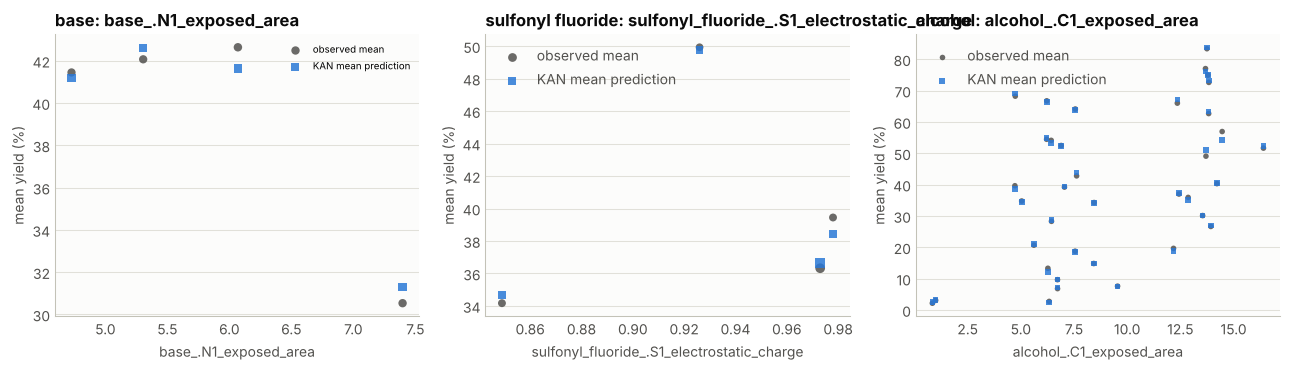

In [12]:
cls = pd.Series(np.select([raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1], ["primary", "secondary", "tertiary"], "other"), index=raw.index)
print("Mean yield by alcohol class and base (N1 exposed area):")
print(pd.DataFrame({"class": cls, "base": raw["base_.N1_exposed_area"], "yield": y}).pivot_table(index="class", columns="base", values="yield", aggfunc="mean").round(1))
print("\nMean yield by alcohol class and sulfonyl fluoride (S1 charge):")
print(pd.DataFrame({"class": cls, "SF": raw["sulfonyl_fluoride_.S1_electrostatic_charge"], "yield": y}).pivot_table(index="class", columns="SF", values="yield", aggfunc="mean").round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, lab in zip(axes, ["base_.N1_exposed_area", "sulfonyl_fluoride_.S1_electrostatic_charge", "alcohol_.C1_exposed_area"],
                        ["base", "sulfonyl fluoride", "alcohol"]):  # fmt: skip
    style_axes(ax)
    mm = model_means(raw[col])
    ax.scatter(mm.index, mm.observed, s=14 + 0.15 * mm.n, color=INK_2, alpha=0.85, linewidths=0, zorder=3, label="observed mean")
    ax.scatter(mm.index, mm.predicted, s=14 + 0.15 * mm.n, marker="s", color=SERIES[0], alpha=0.85, linewidths=0, zorder=4, label="KAN mean prediction")
    finish_axes(ax, f"{lab}: {col}", col, "mean yield (%)")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


### Reading

This dataset is carried by structural flags, and the flags say what the mechanism says.

**Substitution class decides the outcome.** Tertiary alcohols average 3.3 % yield against 42.5 %
for everything else, the largest level difference in the dataset. Primary alcohols average 49.7 %
and secondary 36.5 %. Deoxyfluorination here runs through a sulfonate that fluoride then displaces
in a backside attack, so a tertiary centre eliminates instead of substituting. The KAN reproduces
every level mean to within about two points, except the 20 four-membered-ring reactions, where it
predicts 14.8 % against an observed 21.3 %.

**The other flags are consistent with that picture.** Homoallylic alcohols (3.1 %), those with a
carbonyl beta to the alcohol (7.5 %), allylic alcohols (16.5 %) and six-membered cyclic alcohols
(17.5 %) are the weak cases; benzylic (50.9 %) and alpha-carbonyl (51.4 %) alcohols are the strong
ones. Each rests on 20 to 160 reactions, so these are group means, not fits.

**The base effect depends on the alcohol, which is the paper's point.** Primary alcohols fall from
57.9 % with the smallest base to 31.9 % with the largest, while secondary alcohols barely move,
36.7 to 33.0 %. A single-descriptor rule cannot carry an effect whose sign depends on another
component.

**Pruning removed the primary flag.** It correlates at 0.90 with the exposed area of the alcohol
carbon, which stays; a primary carbon is the most exposed one. The level tables above still show
the class means, because they are computed from the data, not from the model.

**Only one continuous curve survives refitting, and it rests on five reagents.** The fluoride
charge on the sulfonyl fluoride reads as linear in all five refits, but five sulfonyl fluorides
give it five values: a slope through five points. The alcohol electronegativity is labelled
Complex in all five refits, which is consistent but not a reading. The two curves over the
alcohol carbon change shape from fold to fold. Read as accumulated local effects the refits agree
on the shape 60 % of the time, against 35 % for partial effects; with 37 alcohols behind three
continuous alcohol descriptors, the information is in the discrete structural classes.

**Models.** Gradient boosting reaches cross-validated R² 0.931, the random forest 0.907, the KAN
0.855 and the linear model 0.495. The KAN loses to gradient boosting in 15 folds of 15, by the
widest margin in the series: a dataset carried by binary flags suits a tree, not splines.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


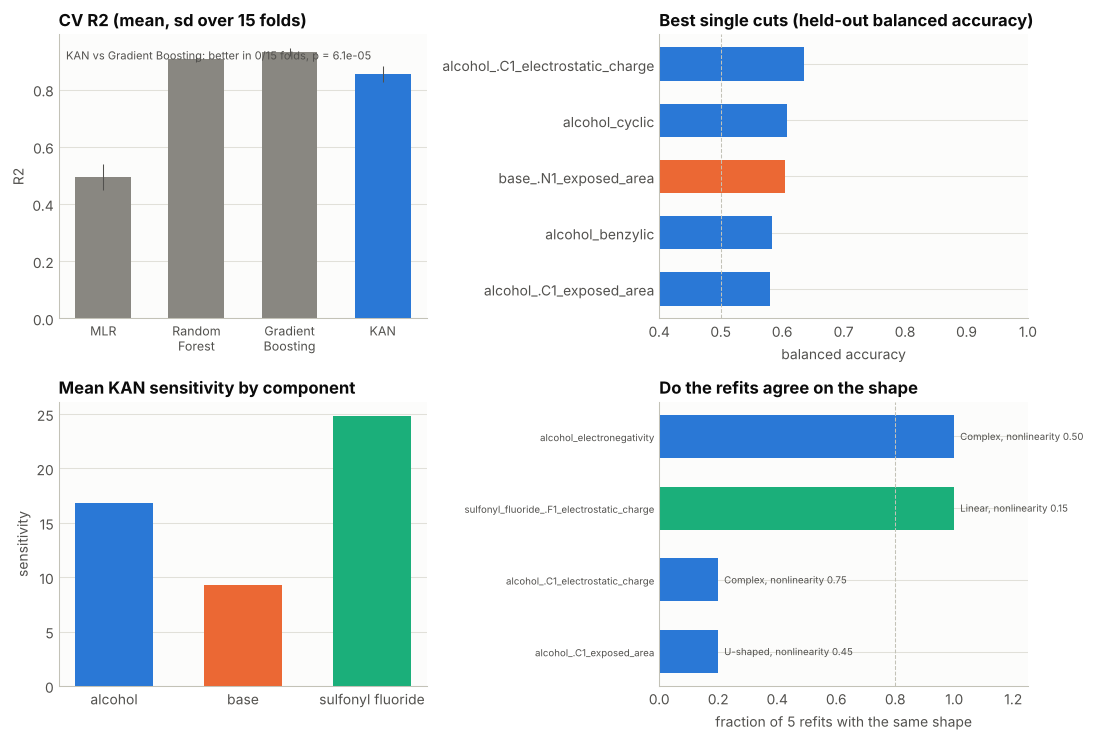

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
